1｜导入库和设置路径
只需要先检查 DATA_DIR。Windows 路径可写成 Path(r"D:\\你的文件夹")。文件名如果不同，可直接修改字典。默认每个模型试 4 组参数，内部做 4 折时序验证。

In [1]:
from importlib.metadata import version
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import display

from alibi.explainers import ALE, PartialDependence, TreeShap
from catboost import CatBoostRegressor, Pool
from lightgbm import LGBMRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from xgboost import XGBRegressor

DATA_DIR = Path.cwd()   # 或改成 Path(r"D:\你的文件夹")
OUTPUT_DIR = DATA_DIR / "WTI_Alibi_Results"

# 键是输出标签，值依次为 Excel 文件名与该表中实际的 Y 列名。
FILES = {
    "Soybean_Oil": ("WTI_to_Soybean_Oil_Six_Factors_Common_Dates.xlsx", "WTI_to_Soybean_Oil"),
    "Wheat": ("WTI_to_Wheat_Six_Factors_Common_Dates.xlsx", "WTI_to_Wheat"),
    "Cotton_No2": ("WTI_to_Cotton_No2_Six_Factors_Common_Dates.xlsx", "WTI_to_Cotton_No2"),
    "Feeder_Cattle": ("WTI_to_Feeder_Cattle_Six_Factors_Common_Dates.xlsx", "WTI_to_Feeder_Cattle"),
    # 如需加入玉米，取消下一行的注释。
    # "Corn": ("WTI_to_Corn_Six_Factors_Common_Dates.xlsx", "WTI_to_Corn"),
}
FEATURE_COLUMNS = {
    "VIX": "VIX",
    "广义美元指数": "USD_Broad",
    "美国经济政策不确定性（EPU）": "EPU",
    "全球地缘政治风险（GPR）": "GPR",
    "波罗的海干散货指数（BDI）": "BDI",
    "Niño 3.4 海温异常（°C）": "Nino34",
}
FEATURES = list(FEATURE_COLUMNS.values())

COMMON_DATES = True      # True：四个品种使用完全相同的有效日期
X_LAG = 0                # 0：同日 X；1：该品种 Excel 的上一条可用日期
TEST_FRACTION = 0.20     # 最后约 20% 的观测为测试样本
CV_SPLITS = 4            # 扩展窗口的验证折数
GAP_ROWS = 0             # CV 和最终训练/测试边界的间隔，单位为建模观测行
SEED = 2026
THREADS = 2
TOP_ALE = 3
PDP_PAIRS = [("VIX", "GPR"), ("BDI", "Nino34")]

# 1 表示只解释 CV 第一名。改成 (1, 2) 可同时解释次优模型。
EXPLAIN_RANKS = (1,)
# 改用滞后或其他设定时，建议修改 RUN_NAME，以保留原结果。
RUN_NAME = f"common{int(COMMON_DATES)}_lag{X_LAG}_gap{GAP_ROWS}"

print("数据目录", DATA_DIR.resolve())
print("输出目录", (OUTPUT_DIR / RUN_NAME).resolve())

IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html


数据目录 D:\mypython\26-11-11部长新论文
输出目录 D:\mypython\26-11-11部长新论文\WTI_Alibi_Results\common1_lag0_gap0


2｜读入 Excel、核对日期和数值
X_LAG = 1 时先在各自的匹配表内取前一条观测，再求跨品种日期交集。此处的前一条观测可能与当日相隔多个自然日。如研究目标是可实时实施的预测，还需用各指标的实际可获得时间重新对齐。

In [2]:
def read_model_table(filename, target):
    path = DATA_DIR / filename
    if not path.is_file():
        raise FileNotFoundError(f"找不到 {path}，请检查 DATA_DIR 和 FILES。")

    raw = pd.read_excel(path, engine="openpyxl")
    expected = ["共同日期", target, *FEATURE_COLUMNS]
    missing = [column for column in expected if column not in raw]
    if missing:
        raise ValueError(f"{path.name} 缺少列 {missing}，实际列名为 {list(raw.columns)}")

    frame = raw[expected].rename(columns={"共同日期": "Date", **FEATURE_COLUMNS})
    frame["Date"] = pd.to_datetime(frame["Date"], errors="raise").dt.normalize()
    if frame["Date"].isna().any() or frame["Date"].duplicated().any():
        raise ValueError(f"{path.name} 的日期有缺失或重复。")

    frame = frame.set_index("Date").sort_index()
    columns = [target, *FEATURES]
    frame[columns] = frame[columns].apply(pd.to_numeric, errors="raise")
    if not np.isfinite(frame[columns].to_numpy(dtype=float)).all():
        raise ValueError(f"{path.name} 含缺失值或无穷值，请核对原表。")

    # 持续性基准使用本品种上一条原表观测的溢出值。
    frame["Y_previous"] = frame[target].shift(1)
    frame["Y_previous_date"] = frame.index.to_series().shift(1)
    frame["X_date"] = frame.index.to_series().shift(X_LAG)
    frame[FEATURES] = frame[FEATURES].shift(X_LAG)
    return frame.dropna(subset=FEATURES).copy()


if not isinstance(X_LAG, int) or X_LAG < 0:
    raise ValueError("X_LAG 应为非负整数。")
if not 0 < TEST_FRACTION < 1 or GAP_ROWS < 0:
    raise ValueError("检查 TEST_FRACTION 与 GAP_ROWS。")

datasets = {name: read_model_table(*spec) for name, spec in FILES.items()}
if COMMON_DATES:
    indices = iter(frame.index for frame in datasets.values())
    common_index = next(indices)
    for date_index in indices:
        common_index = common_index.intersection(date_index)
    common_index = common_index.sort_values()
    datasets = {name: frame.loc[common_index].copy() for name, frame in datasets.items()}

sample_rows = []
splits = {}
for name, frame in datasets.items():
    test_start = len(frame) - int(np.ceil(len(frame) * TEST_FRACTION))
    train_end = test_start - GAP_ROWS
    if train_end <= (CV_SPLITS + 1) * (GAP_ROWS + 10):
        raise ValueError(f"{name} 的样本太少，无法按当前配置切分。")

    dev, test = frame.iloc[:train_end], frame.iloc[test_start:]
    splits[name] = (dev, test)
    sample_rows.append({
        "Market": name, "First_date": frame.index.min(), "Last_date": frame.index.max(),
        "N": len(frame), "N_development": len(dev), "N_test": len(test),
        "Development_end": dev.index.max(), "Test_start": test.index.min(),
    })

sample_summary = pd.DataFrame(sample_rows)
display(sample_summary)

,Market,First_date,Last_date,N,N_development,N_test,Development_end,Test_start
0,Soybean_Oil,2013-06-19,2026-11-02,3224,2579,645,2024-03-07,2024-03-08
1,Wheat,2013-06-19,2026-11-02,3224,2579,645,2024-03-07,2024-03-08
2,Cotton_No2,2013-06-19,2026-11-02,3224,2579,645,2024-03-07,2024-03-08
3,Feeder_Cattle,2013-06-19,2026-11-02,3224,2579,645,2024-03-07,2024-03-08


3｜设定五个回归模型和参数网格
所有模型使用同样的六列和交叉验证折。基准 Persistence 使用上一条已观测的溢出值，只用于比较误差。训练过程保留溢出指数的原始量纲，便于解释。

In [3]:
def model_candidates():
    return {
        "LightGBM": (
            LGBMRegressor(
                random_state=SEED, n_jobs=THREADS, verbosity=-1,
                learning_rate=0.05, deterministic=True, force_col_wise=True,
            ),
            {"n_estimators": [150, 300], "num_leaves": [7, 15]},
        ),
        "RF": (
            RandomForestRegressor(
                n_estimators=300, random_state=SEED, n_jobs=THREADS,
            ),
            {"max_depth": [4, 8], "min_samples_leaf": [10, 25]},
        ),
        "CatBoost": (
            CatBoostRegressor(
                loss_function="RMSE", random_seed=SEED, thread_count=THREADS,
                learning_rate=0.05, verbose=False, allow_writing_files=False,
            ),
            {"iterations": [150, 300], "depth": [3, 5]},
        ),
        "XGBoost": (
            XGBRegressor(
                objective="reg:squarederror", random_state=SEED,
                n_jobs=THREADS, learning_rate=0.05, tree_method="hist",
            ),
            {"n_estimators": [150, 300], "max_depth": [2, 4]},
        ),
        "GBR": (
            GradientBoostingRegressor(random_state=SEED, learning_rate=0.05),
            {"n_estimators": [150, 300], "max_depth": [2, 3]},
        ),
    }


def test_metrics(actual, predicted):
    errors = np.asarray(actual, dtype=float) - np.asarray(predicted, dtype=float)
    return {
        "Test_RMSE": float(np.sqrt(np.mean(errors ** 2))),
        "Test_MAE": float(mean_absolute_error(actual, predicted)),
        "Test_R2": float(r2_score(actual, predicted)),
    }

4｜时序交叉验证、选择主模型和测试集评估
按扩展窗口验证的平均 RMSE 排名。每个模型用自己的最佳参数在整个开发集重拟合一次，再预测留出测试集。正文主模型取 CV_rank = 1。测试集 R² 采用 sklearn 的定义，另报告相对持续性基准的 RMSE 改善率。

In [4]:
run_dir = OUTPUT_DIR / RUN_NAME
run_dir.mkdir(parents=True, exist_ok=True)
sample_summary.to_csv(run_dir / "sample_dates.csv", index=False, encoding="utf-8-sig")

scores = []
cv_trials = []
fitted = {}
for name, (dev, test) in splits.items():
    target = FILES[name][1]
    x_dev, y_dev = dev[FEATURES], dev[target]
    x_test, y_test = test[FEATURES], test[target]
    cv = TimeSeriesSplit(n_splits=CV_SPLITS, gap=GAP_ROWS)
    market_dir = run_dir / name
    market_dir.mkdir(exist_ok=True)
    if test["Y_previous"].isna().any():
        raise ValueError(f"{name} 的测试集中缺少持续性基准的上一条观测。")
    predictions = pd.DataFrame({
        "Date": test.index,
        "X_date": test["X_date"].to_numpy(),
        "Y_previous_date": test["Y_previous_date"].to_numpy(),
        "Actual": y_test.to_numpy(),
        "Persistence": test["Y_previous"].to_numpy(),
    })
    base = test_metrics(y_test, predictions["Persistence"])
    market_scores = []
    fitted[name] = {}

    for model_name, (estimator, grid) in model_candidates().items():
        print(f"{name} | {model_name}", flush=True)
        search = GridSearchCV(
            estimator, grid, scoring="neg_root_mean_squared_error",
            cv=cv, refit=True, n_jobs=1, error_score="raise",
        )
        search.fit(x_dev, y_dev)
        fitted[name][model_name] = search.best_estimator_
        predictions[model_name] = search.predict(x_test)
        metrics = test_metrics(y_test, predictions[model_name])
        skill = (
            100 * (1 - metrics["Test_RMSE"] / base["Test_RMSE"])
            if base["Test_RMSE"] > 0 else np.nan
        )
        market_scores.append({
            "Market": name, "Model": model_name,
            "CV_RMSE": -search.best_score_,
            "Best_params": json.dumps(search.best_params_, sort_keys=True),
            **metrics, "RMSE_gain_vs_persistence_pct": skill,
        })

        trials = search.cv_results_
        for i, params in enumerate(trials["params"]):
            cv_trials.append({
                "Market": name, "Model": model_name, "Params": json.dumps(params, sort_keys=True),
                "Mean_CV_RMSE": -trials["mean_test_score"][i],
                "SD_CV_RMSE": trials["std_test_score"][i],
                **{f"Fold_{fold + 1}_RMSE": -trials[f"split{fold}_test_score"][i]
                   for fold in range(CV_SPLITS)},
            })

    market_scores.sort(key=lambda row: (row["CV_RMSE"], row["Model"]))
    for rank, row in enumerate(market_scores, start=1):
        row["CV_rank"] = rank
    scores.extend(market_scores)
    scores.append({
        "Market": name, "Model": "Persistence", **base,
        "RMSE_gain_vs_persistence_pct": 0.0,
    })
    predictions.to_csv(market_dir / "test_predictions.csv", index=False, encoding="utf-8-sig")

score_table = pd.DataFrame(scores)
score_table.to_csv(run_dir / "model_comparison.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(cv_trials).to_csv(run_dir / "cv_parameter_trials.csv", index=False, encoding="utf-8-sig")
package_names = [
    "alibi", "shap", "numpy", "scipy", "pandas", "scikit-learn", "xgboost",
    "lightgbm", "catboost", "openpyxl", "matplotlib",
]
(run_dir / "run_settings.json").write_text(
    json.dumps({
        "versions": {package: version(package) for package in package_names},
        "common_dates": COMMON_DATES, "x_lag_rows": X_LAG, "gap_rows": GAP_ROWS,
        "test_fraction": TEST_FRACTION, "cv_splits": CV_SPLITS, "seed": SEED,
        "features": FEATURES, "files": FILES,
    }, indent=2, ensure_ascii=False),
    encoding="utf-8",
)
display(score_table[["Market", "Model", "CV_rank", "CV_RMSE", "Test_RMSE",
                     "Test_MAE", "Test_R2", "RMSE_gain_vs_persistence_pct"]])

Soybean_Oil | LightGBM
Soybean_Oil | RF
Soybean_Oil | CatBoost
Soybean_Oil | XGBoost
Soybean_Oil | GBR
Wheat | LightGBM
Wheat | RF
Wheat | CatBoost
Wheat | XGBoost
Wheat | GBR
Cotton_No2 | LightGBM
Cotton_No2 | RF
Cotton_No2 | CatBoost
Cotton_No2 | XGBoost
Cotton_No2 | GBR
Feeder_Cattle | LightGBM
Feeder_Cattle | RF
Feeder_Cattle | CatBoost
Feeder_Cattle | XGBoost
Feeder_Cattle | GBR


,Market,Model,CV_rank,CV_RMSE,Test_RMSE,Test_MAE,Test_R2,RMSE_gain_vs_persistence_pct
0,Soybean_Oil,CatBoost,1.0,4.611080,5.630340,4.617914,-2.524276,-1719.435545
1,Soybean_Oil,XGBoost,2.0,4.641073,5.087307,4.030171,-1.877244,-1543.955415
2,Soybean_Oil,LightGBM,3.0,4.783458,5.032506,4.045354,-1.815589,-1526.246516
3,Soybean_Oil,RF,4.0,4.798021,3.662199,2.869332,-0.491024,-1083.434090
4,Soybean_Oil,GBR,5.0,4.804032,5.163215,3.958340,-1.963747,-1568.484953
5,Soybean_Oil,Persistence,NaN,NaN,0.309455,0.203246,0.989354,0.000000
6,Wheat,CatBoost,1.0,3.488112,6.935412,5.931781,-5.827352,-2904.474983
7,Wheat,XGBoost,2.0,3.497851,6.778845,5.707448,-5.522575,-2836.648652
8,Wheat,RF,3.0,3.507884,9.362534,8.197543,-11.442126,-3955.923373
9,Wheat,GBR,4.0,3.512068,6.840403,5.800133,-5.641575,-2863.316151


5｜TreeSHAP：变量排序、贡献方向和逐日归因
对各品种测试集计算 TreeSHAP。平均绝对 SHAP 反映贡献大小。某日 SHAP 为正，表示该变量对当日模型输出作正向贡献。代码检查基准值与六个 SHAP 值之和能否重建模型输出。当前版本组合下，CatBoost 回归的 Alibi TreeShap 包装器在初始化时存在兼容问题。CatBoost 因此使用自身的原生 TreeSHAP 接口，其他四种模型使用 Alibi TreeShap。所有模型的 ALE 和 PDP 都由 Alibi 计算。

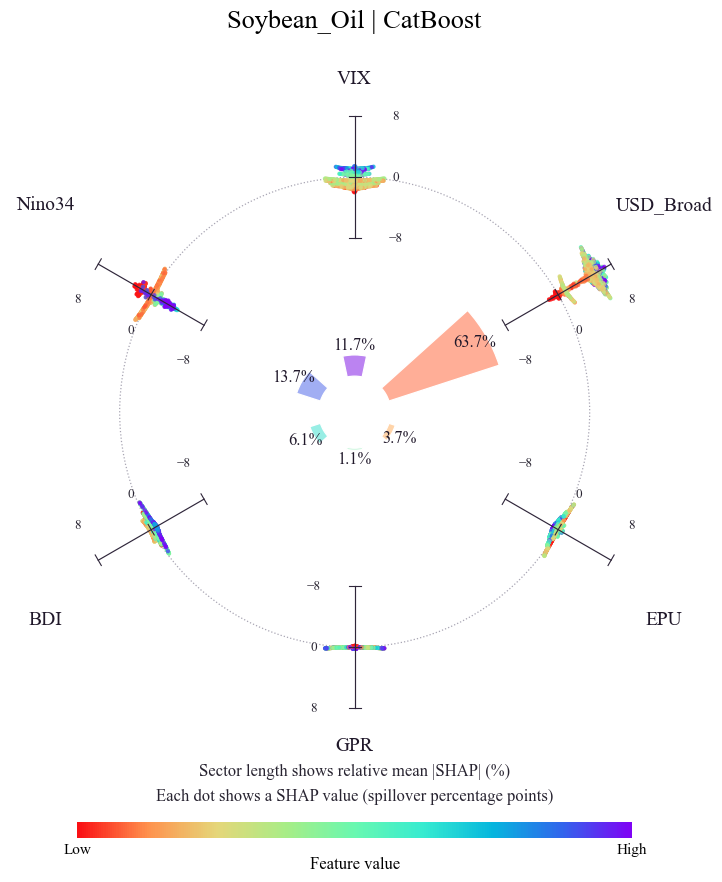

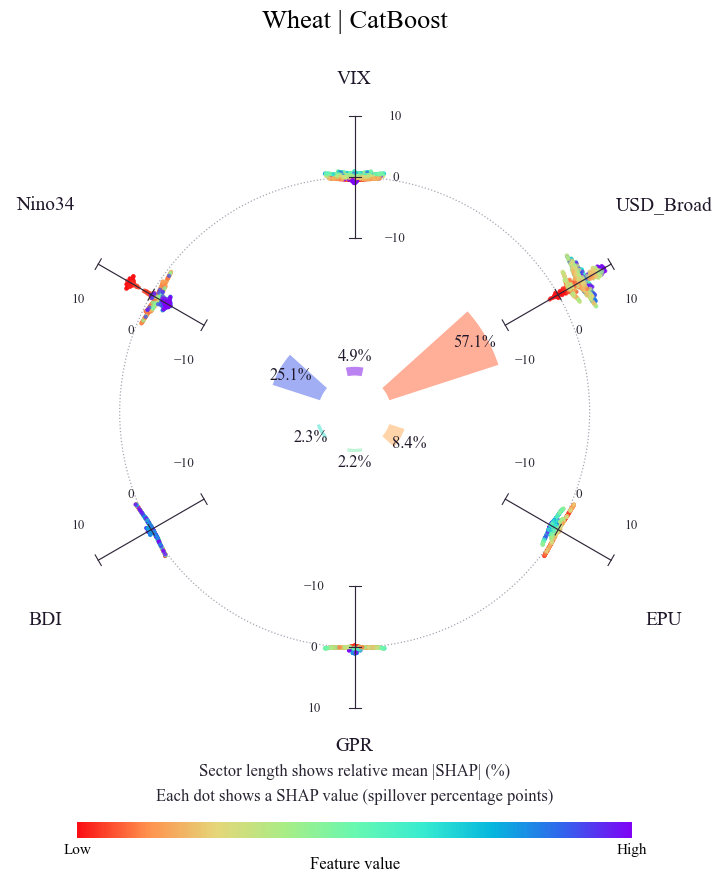

[23:52:43] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0b3782d1791676daf-1\xgboost\xgboost-ci-windows\src\c_api\c_api.cc:1240: Saving into deprecated binary model format, please consider using `json` or `ubj`. Model format will default to JSON in XGBoost 2.2 if not specified.


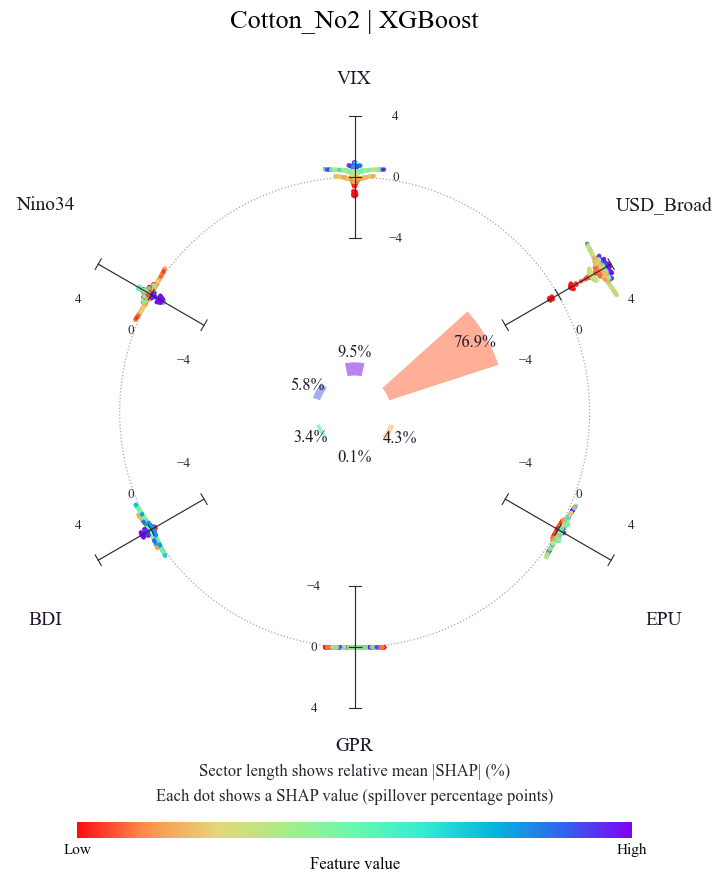

[23:52:44] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0b3782d1791676daf-1\xgboost\xgboost-ci-windows\src\c_api\c_api.cc:1240: Saving into deprecated binary model format, please consider using `json` or `ubj`. Model format will default to JSON in XGBoost 2.2 if not specified.


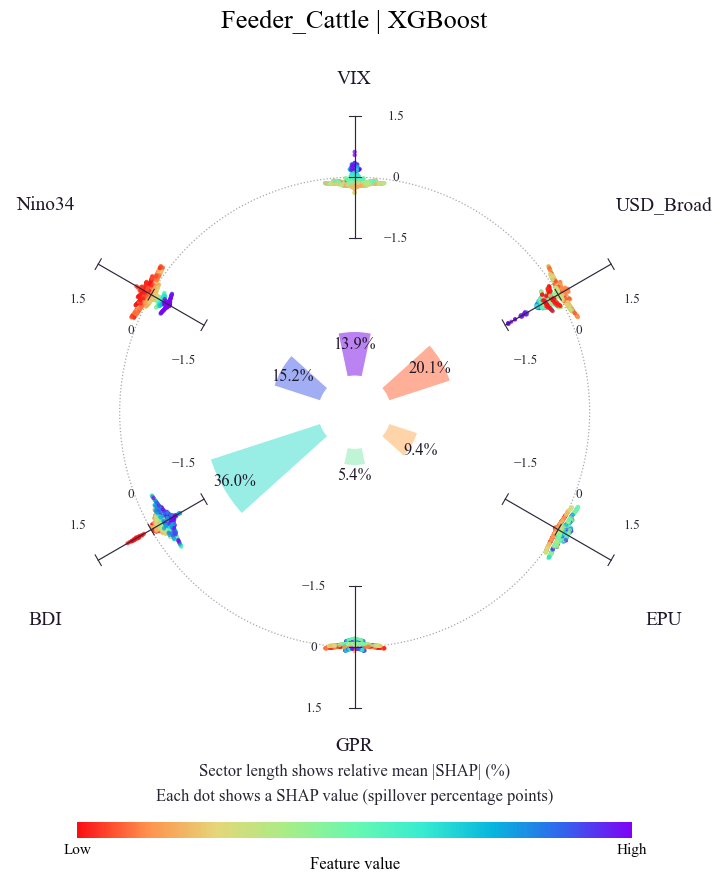

,Market,Model,SHAP_backend,Feature,Mean_abs_SHAP,Relative_SHAP_pct
0,Soybean_Oil,CatBoost,CatBoost native TreeSHAP,USD_Broad,4.335263,63.717413
1,Soybean_Oil,CatBoost,CatBoost native TreeSHAP,Nino34,0.935172,13.744662
2,Soybean_Oil,CatBoost,CatBoost native TreeSHAP,VIX,0.793364,11.660443
3,Soybean_Oil,CatBoost,CatBoost native TreeSHAP,BDI,0.413871,6.082865
4,Soybean_Oil,CatBoost,CatBoost native TreeSHAP,EPU,0.249555,3.667835
5,Soybean_Oil,CatBoost,CatBoost native TreeSHAP,GPR,0.076665,1.126781
6,Wheat,CatBoost,CatBoost native TreeSHAP,USD_Broad,4.199289,57.058250
7,Wheat,CatBoost,CatBoost native TreeSHAP,Nino34,1.848980,25.123203
8,Wheat,CatBoost,CatBoost native TreeSHAP,EPU,0.620707,8.433916
9,Wheat,CatBoost,CatBoost native TreeSHAP,VIX,0.361657,4.914055


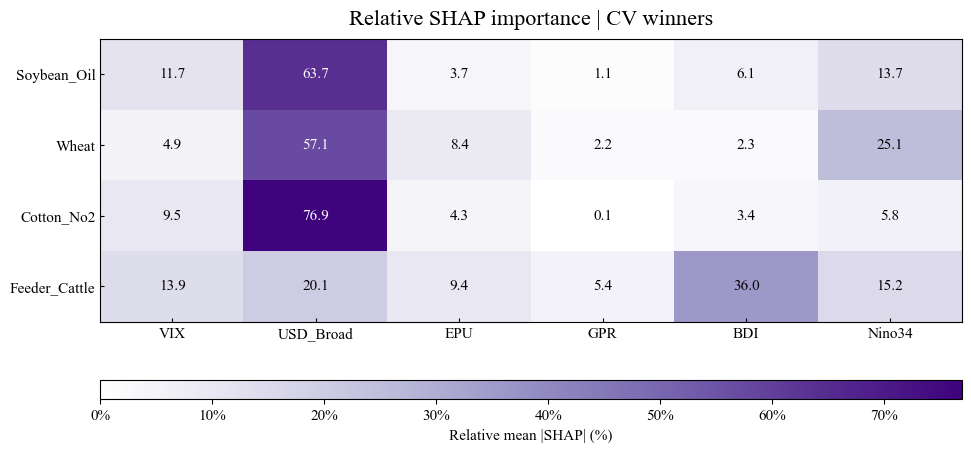

In [5]:
"""替换原 Notebook 中从 def tree_shap_values 到 SHAP 热图结尾的整段代码。

先运行前面的数据和模型训练单元格。保留原有 TreeShap、CatBoostRegressor、
Pool 导入，以及 FEATURES、EXPLAIN_RANKS、THREADS、FILES、score_table、
splits、fitted、run_dir。将本文件内容复制到原单元格中运行。
"""

from pathlib import Path
from textwrap import fill

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Circle, Wedge
from matplotlib.ticker import MaxNLocator, PercentFormatter

# 一般留空。若系统未注册字体，可填写 Times New Roman 正常体的文件路径。
# 例如 macOS: "/System/Library/Fonts/Supplemental/Times New Roman.ttf"
# 例如 Windows: r"C:\Windows\Fonts\times.ttf"
TIMES_NEW_ROMAN_FILE = None

FEATURE_CMAP = LinearSegmentedColormap.from_list(
    "feature_value",
    [
        "#FA1014", "#FF914D", "#E5D679", "#A8ED86", "#68F8B0",
        "#36EBD0", "#05B6DE", "#3165EC", "#7F03F5",
    ],
)
IMPORTANCE_COLORS = ["#BB83F1", "#FFAE97", "#FFD4A9", "#BFF4D6", "#98EEE5", "#A1AEF3"]
HEATMAP_CMAP = LinearSegmentedColormap.from_list(
    "reference_purples",
    ["#FFFFFF", "#E2E0EE", "#BDBDDB", "#958FC3", "#7563AE", "#582F91", "#3F037D"],
)
HEATMAP_CMAP.set_bad("#F4F4F4")


def times_new_roman_style():
    """确认字体可用，避免 Matplotlib 静默换成其他字体。"""
    family = "Times New Roman"
    if TIMES_NEW_ROMAN_FILE:
        font_path = Path(TIMES_NEW_ROMAN_FILE).expanduser()
        if not font_path.is_file():
            raise FileNotFoundError(f"找不到 TIMES_NEW_ROMAN_FILE 指定的字体文件：{font_path}")
        font_manager.fontManager.addfont(font_path)
    try:
        font_manager.findfont(family, fallback_to_default=False)
    except ValueError as exc:
        raise RuntimeError(
            "当前 Python 环境找不到 Times New Roman。"
            "请安装该字体后重启 Notebook 内核，或在 TIMES_NEW_ROMAN_FILE 中填写字体文件路径。"
        ) from exc
    return {
        "font.family": [family],
        "font.size": 11,
        "mathtext.fontset": "custom",
        "mathtext.rm": family,
        "mathtext.it": f"{family}:italic",
        "mathtext.bf": f"{family}:bold",
    }


def tree_shap_values(model, x):
    """返回 SHAP 矩阵、模型基准值和使用的实现。"""
    if isinstance(model, CatBoostRegressor):
        # Alibi 0.9.6 + SHAP 0.43.0 包装 CatBoost 时会缺少 num_outputs。
        values = model.get_feature_importance(
            data=Pool(x), type="ShapValues", thread_count=THREADS,
        )
        np.testing.assert_allclose(values[:, -1], values[0, -1])
        return values[:, :-1], float(values[0, -1]), "CatBoost native TreeSHAP"

    tree = TreeShap(model, model_output="raw", feature_names=FEATURES, task="regression")
    tree.fit()
    explanation = tree.explain(x.to_numpy(dtype=float))
    values = np.asarray(explanation.shap_values[0], dtype=float)
    expected = float(np.asarray(explanation.expected_value).reshape(-1)[0])
    return values, expected, "Alibi TreeShap"


def beeswarm_offsets(values, limit):
    """沿垂直于辐条的方向错开点。每个点的 SHAP 坐标保持原值。"""
    bins = np.rint(52 * (values / limit + 1) / 2).astype(int)
    offsets = np.zeros(len(values), dtype=float)
    order = np.argsort(values, kind="stable")
    for indices in np.split(order, np.flatnonzero(np.diff(bins[order])) + 1):
        stack = np.arange(len(indices))
        offsets[indices] = ((stack + 1) // 2) * np.where(stack % 2, 1, -1)
    step = min(0.024, 0.19 / max(1.0, np.abs(offsets).max()))
    return step * offsets


def feature_point_colors(series):
    """按单一变量的第 5、95 百分位映射散点颜色。"""
    values = series.to_numpy(dtype=float, na_value=np.nan)
    valid = np.isfinite(values)
    scaled = np.full(len(values), 0.5)
    if valid.any():
        low, high = np.percentile(values[valid], [5, 95])
        if low == high:
            low, high = values[valid].min(), values[valid].max()
        if low < high:
            scaled[valid] = np.clip((values[valid] - low) / (high - low), 0, 1)
    colors = FEATURE_CMAP(scaled)
    colors[~valid] = mpl.colors.to_rgba("#8C8C8C")
    return colors


def plot_radial_shap(effects, x_test, importance, name, model_name, plot_dir):
    # 六个变量按 FEATURES 顺序从正上方顺时针排列。
    features = effects.columns
    percentage = importance.set_index("Feature")["Relative_SHAP_pct"].reindex(features)
    max_importance = float(percentage.max())
    max_abs_shap = float(np.abs(effects.to_numpy()).max())
    # 每张图六条辐轴共享同一对称尺度，所有测试样本散点均参与绘制。
    locator = MaxNLocator(nbins=6, steps=[1, 2, 2.5, 5, 10])
    limit = locator.tick_values(0, max_abs_shap)[-1] if max_abs_shap > 0 else 1.0
    ticks = (-limit, 0.0, limit)
    zero_radius, half_span = 1.50, 0.39

    fig = plt.figure(figsize=(9.4, 9.4), facecolor="white")
    ax = fig.add_axes([0.035, 0.17, 0.93, 0.74], aspect="equal")
    ax.set(xlim=(-2.2, 2.2), ylim=(-2.20, 2.24))
    ax.set_axis_off()
    ax.add_patch(Circle(
        (0, 0), zero_radius, fill=False, ec="#A8A5B3", lw=0.9, ls=":", zorder=1,
    ))
    fig.text(0.5, 0.946, f"{name} | {model_name}", ha="center", fontsize=19)

    angles = 90 - 60 * np.arange(len(features))
    for feature, angle, color in zip(features, angles, IMPORTANCE_COLORS):
        theta = np.deg2rad(angle)
        radial = np.array([np.cos(theta), np.sin(theta)])
        tangent = np.array([-radial[1], radial[0]])

        # 彩色扇形的径向长度按相对重要性线性缩放。
        share = percentage.loc[feature]
        inner = 0.23
        length = 0.74 * share / max_importance if max_importance else 0.0
        if length > 0:
            ax.add_patch(Wedge(
                (0, 0), inner + length, angle - 12, angle + 12,
                width=length, facecolor=color, edgecolor="white", lw=0.9, zorder=2,
            ))
        share_radius = inner + length + (-0.085 if length >= 0.20 else 0.06)
        ax.text(
            *(radial * share_radius), f"{share:.1f}%",
            ha="center", va="center", fontsize=12, color="#20182A", zorder=4,
        )

        values = effects[feature].to_numpy()
        radii = zero_radius + half_span * (values / limit)
        offsets = beeswarm_offsets(values, limit)
        points = radii[:, None] * radial + offsets[:, None] * tangent
        point_size = float(np.clip(5500 / len(values), 9, 23))
        ax.scatter(
            points[:, 0], points[:, 1], s=point_size,
            c=feature_point_colors(x_test[feature]), alpha=0.75, linewidths=0, zorder=3,
        )

        ends = np.outer([zero_radius - half_span, zero_radius + half_span], radial)
        ax.plot(*ends.T, color="#2F263A", lw=0.85, zorder=4)
        # 刻度标签放在散点带的一侧，避免盖住蜂群。
        tick_label_side = tangent if radial[0] * radial[1] < -0.1 else -tangent
        for tick in ticks:
            position = (zero_radius + half_span * tick / limit) * radial
            tick_ends = position + np.outer([-0.039, 0.039], tangent)
            ax.plot(*tick_ends.T, color="#2F263A", lw=0.8, zorder=4)
            label = f"{tick:.3g}".replace("-", "−", 1) if tick < 0 else f"{tick:.3g}"
            ax.text(
                *(position + 0.26 * tick_label_side), label, va="center", ha="center",
                color="#282431", fontsize=9.5, zorder=5,
            )
        name_position = radial * 2.13
        if abs(radial[0]) > 0.5:
            name_position += [0.15 * radial[0], 0.26 * np.sign(radial[1])]
        ax.text(
            *name_position, fill(str(feature), width=23),
            va="center", ha="center", fontsize=14, color="#20182A", zorder=5,
        )

    fig.text(
        0.5, 0.150, "Sector length shows relative mean |SHAP| (%)",
        ha="center", fontsize=12, color="#282431",
    )
    fig.text(
        0.5, 0.124, "Each dot shows a SHAP value (spillover percentage points)",
        ha="center", fontsize=12, color="#282431",
    )
    color_ax = fig.add_axes([0.205, 0.084, 0.59, 0.017])
    colorbar = fig.colorbar(
        mpl.cm.ScalarMappable(norm=Normalize(0, 1), cmap=FEATURE_CMAP),
        cax=color_ax, orientation="horizontal", ticks=[0, 1],
    )
    colorbar.set_ticklabels(["Low", "High"])
    colorbar.ax.tick_params(length=0)
    colorbar.outline.set_visible(False)
    fig.text(0.5, 0.056, "Feature value", ha="center", va="center", fontsize=12)
    fig.savefig(plot_dir / "TreeSHAP_radial.png", dpi=300, bbox_inches="tight", pad_inches=0.20)
    plt.show()
    plt.close(fig)


def plot_main_heatmap(heatmap, run_dir):
    matrix = heatmap.to_numpy(dtype=float)
    fig, ax = plt.subplots(
        figsize=(9.6, max(4.0, 2.6 + 0.46 * len(heatmap))),
        layout="constrained",
    )
    image = ax.imshow(
        np.ma.masked_invalid(matrix), cmap=HEATMAP_CMAP, aspect="auto",
        interpolation="nearest", vmin=0, vmax=max(float(np.nanmax(matrix)), 1.0),
    )
    feature_labels = [fill(str(feature), width=20) for feature in heatmap.columns]
    ax.set_xticks(range(len(feature_labels)), feature_labels)
    ax.set_yticks(range(len(heatmap.index)), heatmap.index)
    ax.set_title("Relative SHAP importance | CV winners", pad=10, fontsize=16)
    ax.tick_params(direction="in", length=3)
    for (i, j), value in np.ndenumerate(matrix):
        if np.isfinite(value):
            r, g, b, _ = image.cmap(image.norm(value))
            rgb = np.array([r, g, b])
            linear = np.where(rgb <= 0.04045, rgb / 12.92, ((rgb + 0.055) / 1.055) ** 2.4)
            luminance = linear @ np.array([0.2126, 0.7152, 0.0722])
            label_color = "white" if luminance < 0.179 else "black"
            ax.text(j, i, f"{value:.1f}", ha="center", va="center", color=label_color)
    colorbar = fig.colorbar(
        image, ax=ax, orientation="horizontal", fraction=0.072, pad=0.13, aspect=45,
        format=PercentFormatter(xmax=100, decimals=0),
    )
    colorbar.set_label("Relative mean |SHAP| (%)")
    fig.savefig(run_dir / "TreeSHAP_main_heatmap.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


if len(FEATURES) != 6 or len(set(FEATURES)) != 6:
    raise ValueError("六辐圆环图要求 FEATURES 包含六个不同的变量名。")

selected = score_table[score_table["CV_rank"].isin(EXPLAIN_RANKS)].copy()
if selected.empty:
    raise ValueError("EXPLAIN_RANKS 中至少应包含一个有效的 CV 排名（1–5）。")

importance_tables = []
explanation_jobs = {}
with mpl.rc_context(times_new_roman_style()):
    for row in selected.itertuples(index=False):
        name, model_name = row.Market, row.Model
        _, test = splits[name]
        model = fitted[name][model_name]
        x_test = test[FEATURES]
        plot_dir = run_dir / name / model_name
        plot_dir.mkdir(parents=True, exist_ok=True)

        shap_values, expected, backend = tree_shap_values(model, x_test)
        predicted = model.predict(x_test)
        if shap_values.shape != x_test.shape:
            raise ValueError(f"{name}/{model_name}：SHAP 输出维度异常 {shap_values.shape}。")
        np.testing.assert_allclose(
            expected + shap_values.sum(axis=1), predicted, rtol=2e-4, atol=1e-4,
            err_msg=f"{name}/{model_name}：SHAP 加总校验失败。",
        )

        effects = pd.DataFrame(shap_values, index=x_test.index, columns=FEATURES)
        daily = effects.add_prefix("SHAP_").join(x_test.add_prefix("X_"))
        daily.insert(0, "Base_value", expected)
        daily.insert(1, "Prediction", predicted)
        daily.to_csv(plot_dir / "TreeSHAP_daily.csv", encoding="utf-8-sig")

        importance = (
            effects.abs().mean().rename("Mean_abs_SHAP")
            .sort_values(ascending=False).rename_axis("Feature").reset_index()
        )
        total = importance["Mean_abs_SHAP"].sum()
        importance["Relative_SHAP_pct"] = 100 * importance["Mean_abs_SHAP"] / total if total > 0 else 0.0
        importance.insert(0, "Market", name)
        importance.insert(1, "Model", model_name)
        importance.insert(2, "SHAP_backend", backend)
        importance.to_csv(plot_dir / "TreeSHAP_importance.csv", index=False, encoding="utf-8-sig")
        importance_tables.append(importance)
        explanation_jobs[(name, model_name)] = (model, x_test, plot_dir, importance["Feature"].tolist())

        plot_radial_shap(effects, x_test, importance, name, model_name, plot_dir)

    all_importance = pd.concat(importance_tables, ignore_index=True)
    all_importance.to_csv(run_dir / "TreeSHAP_all_importance.csv", index=False, encoding="utf-8-sig")
    display(all_importance)

    # 跨品种比较只汇总每个品种的 CV 第一名，使用同一套变量顺序。
    main_models = selected.loc[selected["CV_rank"].eq(1), ["Market", "Model"]]
    main_importance = all_importance.merge(main_models, on=["Market", "Model"])
    if not main_importance.empty:
        heatmap = main_importance.pivot(
            index="Market", columns="Feature", values="Relative_SHAP_pct",
        ).reindex(index=list(FILES), columns=FEATURES)
        plot_main_heatmap(heatmap, run_dir)
